# Baseline Model: Logistic Regression
**IST 707 – Applied Machine Learning · Final Project**

---

This notebook builds the trained baseline for predicting whether a hard drive fails in the next 30 days
(Task 6 in `WORKPLAN.md`). It is the reference point that the final tuned model has to beat.

The baseline is deliberately simple: a plain logistic regression with default regularization, no feature
engineering beyond what the model needs to run, and no hyperparameter search. The only choice tuned is the
decision threshold, chosen on a validation fold.

| § | Section | Purpose |
|---|---|---|
| 1 | Setup | Libraries and data loading (train and calib only) |
| 2 | Features | Which columns go into the model and why |
| 3 | Pipeline | Imputation, scaling and encoding |
| 4 | Time-aware validation | Fit on older windows, validate on the most recent ones |
| 5 | Threshold selection | Pick the cut-off on the validation fold |
| 6 | Calibration set | Performance at true prevalence, ranking at a replacement budget, recalibration |
| 7 | Summary | Baseline numbers to carry forward |

`modeling_test.parquet` is **not** opened here, per the data snooping rule.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
DATA_DIR = "../data/modeling"
SEED = 42

### 1.1 Loading the data
Train is sampled to 20:1 (healthy:failing). Calib holds November and December 2024 at the true prevalence
(about 1 in 905). Both load in full.

In [2]:
train = pd.read_parquet(f"{DATA_DIR}/modeling_train.parquet")
calib = pd.read_parquet(f"{DATA_DIR}/modeling_calib.parquet")

for name, d in [("train", train), ("calib", calib)]:
    print(f"{name:>5}: {len(d):>7,} rows | {int(d.label.sum()):>5,} failures | 1 in {len(d)/d.label.sum():,.0f} | windows {d.window.min()}–{d.window.max()}")

train: 169,827 rows | 8,087 failures | 1 in 21 | windows 0–21
calib: 297,009 rows |   328 failures | 1 in 906 | windows 22–23


## 2. Features

What goes in, following the data card and the EDA conclusions:

- **Raw SMART attributes** (first, last, delta for each). The EDA showed raw values carry more failure signal
  than the vendor-normalized ones, and that normalized values mostly encode the manufacturer.
- **Normalized SMART attributes are dropped** for the same reason.
- **SMART 4 is dropped**: it is almost perfectly correlated with SMART 12 (ρ = 0.997).
- **`model`**, one-hot encoded, so the model can learn per-model base rates. Unseen models in later periods are
  ignored instead of raising an error.
- **`capacity_bytes`, `days_observed`, `days_span`**. Capacity `-1` is Backblaze's "unknown" code and becomes
  missing.
- **Not used:** the five bookkeeping columns (`serial_number`, `window`, `window_first_date`,
  `window_last_date`, `label`) and `drive_days_to_date`, which counts days since 2023-01-01 and so tracks the
  calendar rather than the drive.

In [3]:
for d in (train, calib):
    d["capacity_bytes"] = d["capacity_bytes"].replace(-1, np.nan)

RAW_SMART = [c for c in train.columns
             if c.startswith("smart_") and "_raw_" in c and not c.startswith("smart_4_")]
NUM_COLS = RAW_SMART + ["capacity_bytes", "days_observed", "days_span"]
CAT_COLS = ["model"]
FEATURES = NUM_COLS + CAT_COLS

print(f"{len(RAW_SMART)} raw SMART features + 3 numeric descriptors + model ({train.model.nunique()} categories in train)")

39 raw SMART features + 3 numeric descriptors + model (63 categories in train)


## 3. Pipeline

Logistic regression is sensitive to scale and cannot take missing values, so every numeric column goes through:

1. **Median imputation**: only SMART 197 (about 2%) and SMART 193 (about 0.1%) have missing values.
2. **Signed log transform**, `sign(x)·log(1+|x|)`. Raw counters span many orders of magnitude (power-on
   hours in the tens of thousands next to sector counts in single digits), and deltas can be negative.
3. **Standard scaling**, fit on the training rows only.

`model` is one-hot encoded. The classifier uses scikit-learn defaults (`C = 1.0`, L2 penalty) and no class
weights, since train is already rebalanced to 20:1.

In [4]:
def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

def make_baseline():
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(signed_log)),
        ("scale", StandardScaler()),
    ])
    pre = ColumnTransformer([
        ("num", numeric, NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, random_state=SEED))])

make_baseline()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

## 4. Time-aware validation

The splits are chronological, so validation has to be too. A random split would put a drive's
earlier windows in training and its later windows in validation, which leaks information.

The training split covers windows 0–21 (Jan 2023 to Oct 2024). The model is fit on **windows 0–17** and validated
on **windows 18–21**, the most recent four months, which mirrors how it will be used: trained on the past,
scored on the future. The validation fold keeps train's 20:1 sampling.

In [5]:
fit_mask = train.window <= 17
val_mask = train.window >= 18
X_fit, y_fit = train.loc[fit_mask, FEATURES], train.loc[fit_mask, "label"]
X_val, y_val = train.loc[val_mask, FEATURES], train.loc[val_mask, "label"]
print(f"fit: {len(X_fit):,} rows ({y_fit.sum():,} failures) | validation: {len(X_val):,} rows ({y_val.sum():,} failures)")

lr = make_baseline().fit(X_fit, y_fit)
p_val = lr.predict_proba(X_val)[:, 1]

def scores(y, pred, prob=None):
    out = {"recall": recall_score(y, pred), "precision": precision_score(y, pred), "F1": f1_score(y, pred)}
    if prob is not None:
        out["PR-AUC"] = average_precision_score(y, prob)
    return out

pd.DataFrame([scores(y_val, p_val >= 0.5, p_val)], index=["validation @ 0.50"])

fit: 136,326 rows (6,483 failures) | validation: 33,501 rows (1,604 failures)


,recall,precision,F1,PR-AUC
validation @ 0.50,0.4021,0.7500,0.5235,0.5656


**Interpretation.** At the default 0.5 cut-off the model is conservative: its precision is high, but it misses
most failures. For drive replacement a missed failure (an outage) costs more than an extra flag (an
early swap), so the threshold is moved to favor recall.

## 5. Threshold selection

The threshold is the value that maximizes F1 on the validation fold. It is chosen here, never on test.

,recall,precision,F1,PR-AUC
validation @ 0.50,0.4021,0.7500,0.5235,0.5656
validation @ 0.158,0.5574,0.6008,0.5783,0.5656


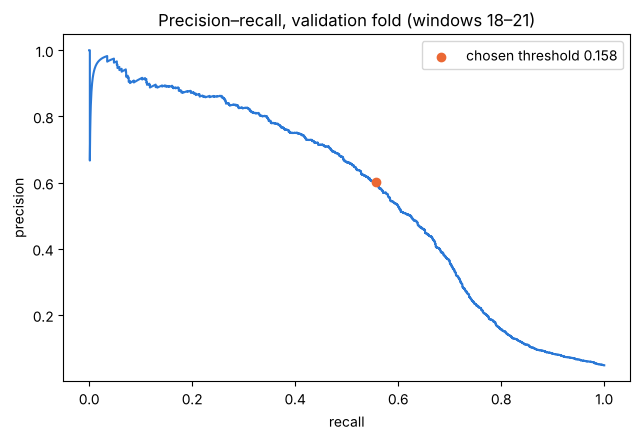

TP 894 | FN 710 | FP 594 | TN 31,303


In [6]:
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[np.argmax(f1)])

val_table = pd.DataFrame([scores(y_val, p_val >= 0.5, p_val), scores(y_val, p_val >= THRESHOLD, p_val)],
                         index=["validation @ 0.50", f"validation @ {THRESHOLD:.3f}"])
display(val_table)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(rec, prec, color="#2a78d6")
ax.scatter(recall_score(y_val, p_val >= THRESHOLD), precision_score(y_val, p_val >= THRESHOLD),
           color="#eb6834", zorder=3, label=f"chosen threshold {THRESHOLD:.3f}")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision–recall, validation fold (windows 18–21)")
ax.legend(); plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_val, p_val >= THRESHOLD).ravel()
print(f"TP {tp:,} | FN {fn:,} | FP {fp:,} | TN {tn:,}")

**Interpretation.** Lowering the threshold trades some precision for recall. At the chosen cut-off the
baseline catches just over half of upcoming failures, and just over half of the drives it flags really
are failing, on the 20:1 validation fold. These are the baseline figures the tuned model is compared against.

## 6. Calibration set: performance at true prevalence

The validation fold is sampled 20:1. Real operations see about **1 failure in 905 windows**, so the same model
looks very different there. The calibration set (Nov–Dec 2024, unsampled) shows this, and it has two jobs here:

1. **Evaluate at true prevalence**: PR-AUC, the fixed threshold, and precision/recall at a replacement budget
   (the proposal's primary metric).
2. **Recalibrate the probabilities.** Training at 20:1 inflates every predicted probability about 45×.
   Platt scaling is fit on calib window 22 and checked on window 23, so the check is out of sample.

The model is refit on all of train (windows 0–21) before scoring calib.

In [7]:
lr_full = make_baseline().fit(train[FEATURES], train["label"])
p_cal = lr_full.predict_proba(calib[FEATURES])[:, 1]
y_cal = calib["label"].values

display(pd.DataFrame([scores(y_cal, p_cal >= THRESHOLD, p_cal)], index=[f"calib @ {THRESHOLD:.3f}"]))
print(f"PR-AUC of a random ranking at this prevalence: {y_cal.mean():.4f}")

,recall,precision,F1,PR-AUC
calib @ 0.158,0.5671,0.0320,0.0606,0.0896


PR-AUC of a random ranking at this prevalence: 0.0011


### 6.1 Precision and recall at a replacement budget

Operators replace a fixed number of drives, so the model ranks drives by risk and the top N per thousand are
flagged.

In [8]:
order = np.argsort(-p_cal)
rows = []
for per_k in [1, 2, 5, 10]:
    n = int(len(p_cal) * per_k / 1000)
    caught = y_cal[order[:n]].sum()
    rows.append({"budget (per 1,000 drives)": per_k, "drives flagged": n, "failures caught": int(caught),
                 "precision": caught / n, "recall": caught / y_cal.sum()})
pd.DataFrame(rows).set_index("budget (per 1,000 drives)")

,drives flagged,failures caught,precision,recall
"budget (per 1,000 drives)",,,,
1,297,50,0.1684,0.1524
2,594,71,0.1195,0.2165
5,1485,112,0.0754,0.3415
10,2970,150,0.0505,0.4573


### 6.2 Recalibration (Platt scaling)

window 23 actual failure rate   : 0.00109
mean predicted, before recalib. : 0.03193
mean predicted, after recalib.  : 0.00174


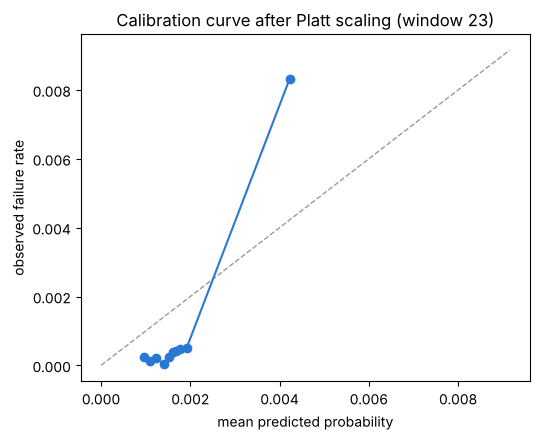

In [9]:
def logit(p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p)).reshape(-1, 1)

w22, w23 = (calib.window == 22).values, (calib.window == 23).values
platt = LogisticRegression().fit(logit(p_cal[w22]), y_cal[w22])
p_recal = platt.predict_proba(logit(p_cal[w23]))[:, 1]

print(f"window 23 actual failure rate   : {y_cal[w23].mean():.5f}")
print(f"mean predicted, before recalib. : {p_cal[w23].mean():.5f}")
print(f"mean predicted, after recalib.  : {p_recal.mean():.5f}")

bins = pd.qcut(p_recal, 10, duplicates="drop")
rel = pd.DataFrame({"pred": p_recal, "obs": y_cal[w23]}).groupby(bins, observed=True).mean()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
lim = max(rel.pred.max(), rel.obs.max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="#9a9a96", lw=1)
ax.plot(rel.pred, rel.obs, "-o", color="#2a78d6")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed failure rate")
ax.set_title("Calibration curve after Platt scaling (window 23)"); plt.tight_layout(); plt.show()

**Interpretation.** At true prevalence precision drops sharply, because healthy drives outnumber failing ones
about 900 to 1. Even a small false-positive rate means many flags. PR-AUC is still far above the random
level, so the ranking is informative. Platt scaling cuts the overestimate in average predicted risk from about
30× to under 2×, but does not remove it, so the baseline's probabilities should not yet be read as real
risk. Raising precision at true prevalence and getting the calibration right are the main targets for the
final model.

## 7. Summary

| | Value |
|---|---|
| Model | Logistic regression, default `C = 1.0`, no tuning |
| Features | Raw SMART first/last/delta (minus SMART 4), capacity, days observed/span, one-hot model |
| Validation | Fit on windows 0–17, validate on 18–21 (20:1 sampled) |
| Threshold | Chosen to maximize F1 on validation |

In [10]:
summary = pd.concat([
    val_table.iloc[[1]],
    pd.DataFrame([scores(y_cal, p_cal >= THRESHOLD, p_cal)], index=[f"calib @ {THRESHOLD:.3f} (true prevalence)"]),
])
summary

,recall,precision,F1,PR-AUC
validation @ 0.158,0.5574,0.6008,0.5783,0.5656
calib @ 0.158 (true prevalence),0.5671,0.0320,0.0606,0.0896


**What the final model has to improve on.** The baseline clears 50% recall and F1 on validation but leaves
clear room: almost half of failures are still missed, and precision at true prevalence is low. The final
model (XGBoost with tuning, then calibration) is judged against these numbers.